# Sales Analysis

## Import packages

In [224]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
sns.set_theme(style="darkgrid")

## Import Data

In [225]:
# Import Sales Data
df_sales = pd.read_excel("Copy of DATASET - Tasks.xlsx", sheet_name="Sales");

# Import Stores Data
df_stores = pd.read_excel("Copy of DATASET - Tasks.xlsx", sheet_name="Stores");

# Take a snapshot of both datasets
print("Sales Data Snapshot------");
print(df_sales.info());
display(df_sales.head());
print("Stores Data Snapshot------");
print(df_stores.info());
display(df_stores.head());

Sales Data Snapshot------
<class 'pandas.DataFrame'>
RangeIndex: 1872 entries, 0 to 1871
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Items Sold  1872 non-null   int64  
 1   Year        1872 non-null   int64  
 2   Month       1872 non-null   str    
 3   Store       1872 non-null   int64  
 4   Sales       1872 non-null   float64
 5   COGS        1872 non-null   float64
 6   Overhead    1872 non-null   float64
dtypes: float64(3), int64(3), str(1)
memory usage: 102.5 KB
None


,Items Sold,Year,Month,Store,Sales,COGS,Overhead
0,2324,2023,June,6548,61586.0,4711.33,615.86
1,343,2023,June,97863,9089.5,695.35,90.90
2,636,2023,June,4651,16854.0,1289.33,168.54
3,1334,2023,June,86582,35351.0,2704.35,353.51
4,3532,2023,June,596,93598.0,7160.25,935.98


Stores Data Snapshot------
<class 'pandas.DataFrame'>
RangeIndex: 104 entries, 0 to 103
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   STORE NO    104 non-null    int64
 1   PROVINCE    104 non-null    str  
 2   REGION      104 non-null    str  
 3   SQ FOOTAGE  104 non-null    int64
 4   COUNT       104 non-null    int64
dtypes: int64(3), str(2)
memory usage: 4.2 KB
None


,STORE NO,PROVINCE,REGION,SQ FOOTAGE,COUNT
0,6548,ONTARIO,EAST,2543,1
1,97863,QUEBEC,EAST,1245,1
2,4651,NEW BRUNSWICK,ATLANTIC,5544,1
3,86582,NOVA SCOTIA,ATLANTIC,3215,1
4,596,SASKATCHEWAN,WEST,9412,1


## Consolidate Data

In [226]:
# Change column name from "Store" to "STORE NO" in Sales data so that it is the same name as the corresponding column in the Stores data
df_sales_adjusted = df_sales.rename(columns={"Store":"STORE NO"});

# Merge Sales and Stores Data by Store (i.e., STORE NO), which is shared data across both datasets
df = pd.merge(df_sales_adjusted, df_stores, on="STORE NO", how="inner");

# Take a snapshot of the consolidated data
print(df.info());
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 1872 entries, 0 to 1871
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Items Sold  1872 non-null   int64  
 1   Year        1872 non-null   int64  
 2   Month       1872 non-null   str    
 3   STORE NO    1872 non-null   int64  
 4   Sales       1872 non-null   float64
 5   COGS        1872 non-null   float64
 6   Overhead    1872 non-null   float64
 7   PROVINCE    1872 non-null   str    
 8   REGION      1872 non-null   str    
 9   SQ FOOTAGE  1872 non-null   int64  
 10  COUNT       1872 non-null   int64  
dtypes: float64(3), int64(5), str(3)
memory usage: 161.0 KB
None


,Items Sold,Year,Month,STORE NO,Sales,COGS,Overhead,PROVINCE,REGION,SQ FOOTAGE,COUNT
0,2324,2023,June,6548,61586.0,4711.33,615.86,ONTARIO,EAST,2543,1
1,343,2023,June,97863,9089.5,695.35,90.90,QUEBEC,EAST,1245,1
2,636,2023,June,4651,16854.0,1289.33,168.54,NEW BRUNSWICK,ATLANTIC,5544,1
3,1334,2023,June,86582,35351.0,2704.35,353.51,NOVA SCOTIA,ATLANTIC,3215,1
4,3532,2023,June,596,93598.0,7160.25,935.98,SASKATCHEWAN,WEST,9412,1


## Analyze the Data

**2022 vs 2023 June Sales by province**

In [227]:
def compareMetricByGivenMonth(dff, month, metric, showValues):
    # Create a dataset filtering data whereby the Month column value is the given month
    df_month = dff[dff["Month"] == month].sort_values(by="PROVINCE", ascending=True);
    df_month = df_month.rename(columns={"PROVINCE":"Province"});
    
    # Create a new dataframe with the following columns: Province, 2022, 2023
    df_agg = df_month.groupby(["Province","Year"])[metric].sum().unstack(fill_value=0).reset_index();
    data = pd.DataFrame({
        "Province": df_agg["Province"],
        # "2022": df_agg[2022],
        # "2023": df_agg[2023]
    });

    for year in df_month["Year"].unique():
        data[year] = df_agg[year];

    # Set title
    title = f"{month} {metric} by Province";
    print(title);

    # Show aggregated dataframe
    display(data);
    
    # Create chart
    chart = sns.catplot(data=df_month, kind="bar", x=metric, y="Province", hue="Year", estimator="sum", errorbar=None, palette="dark").set(title=title);
    
    # Add exact values inside the bars
    for ax in chart.axes.flat:
        # Remove 1e6 scientific notation and add commas
        ax.xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
        if showValues == True:
            for container in ax.containers:
                ax.bar_label(
                    container,
                    fmt="{:,.0f}",
                    label_type="center",
                    color="white",
                    fontsize=9,
                    fontweight="bold"
                );
    
    # Rotate x-axis labels
    chart.tick_params(axis="x", rotation=45);

June Sales by Province


,Province,2022,2023
0,ALBERTA,1296512.5,1343258.5
1,BRITISH COLUMBIA,1622886.5,1669632.5
2,NEW BRUNSWICK,1282891.5,1317951.0
3,NOVA SCOTIA,1397239.0,1440089.5
4,ONTARIO,1482648.5,1517708.0
5,PEI,1615758.0,1662504.0
6,QUEBEC,869041.0,904100.5
7,SASKATCHEWAN,2831737.0,2948602.0


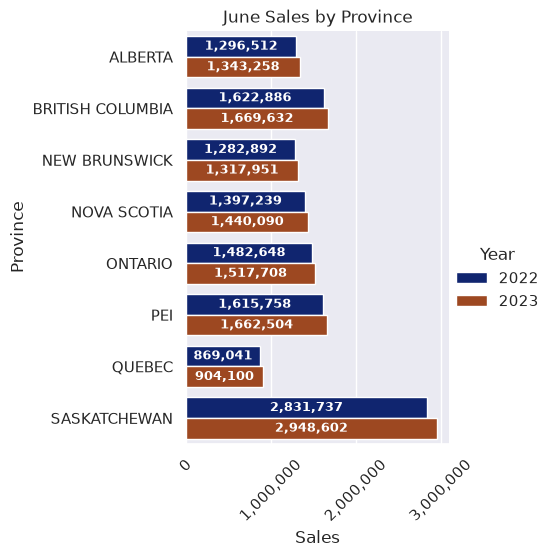

In [228]:
compareMetricByGivenMonth(df, "June", "Sales", True)

**2022 vs 2023 QTD Sales by province**

In [229]:
# Q1: January 1 – March 31
# Q2: April 1 – June 30
# Q3: July 1 – September 30
# Q4: October 1 – December 31

def determineFiscalQuarter(row):
    if row["Month"] in ["January", "February", "March"]:
        return "Q1";
    elif row["Month"] in ["April", "May", "June"]:
        return "Q2";
    elif row["Month"] in ["July", "August", "September"]:
        return "Q3";
    else:
        return "Q4";

In [230]:
def compareMetricByQTD(dff, metric, fiscalQTD, showValues, comparisonType):
    # Create a dataset that determines the fiscal quarter
    df_quarter = dff.rename(columns={"PROVINCE":"Province"}).sort_values(by="Province", ascending=True);
    df_quarter["Quarter"] = dff.apply(lambda row: determineFiscalQuarter(row), axis=1);
    df_quarter["Period"] = df_quarter.apply(lambda row: f"{row["Year"]} {row["Quarter"]}", axis=1);
    df_qtd = df_quarter[df_quarter["Quarter"].isin(fiscalQTD)];

    # Create a new dataframe with the following columns: Province, 2022 Q1, 2023 Q1, 2022 Q2, 2023 Q2
    df_agg = df_qtd.groupby(by=["Province", "Year", "Quarter"])[metric].sum().unstack(["Year","Quarter"]).reset_index();
    data = pd.DataFrame({"Province": df_agg["Province"]});
    # Order data as per a chronological timeline
    if comparisonType == "chronological":
        for year in df_quarter["Year"].unique():
            for quarter in fiscalQTD:
                data[f"{year} {quarter}"] = df_agg[year][quarter];
        df_qtd = df_qtd.sort_values(by=["Province", "Year", "Quarter"], ascending=True);
    # Order data as per side-by-side comparison of quarters
    elif comparisonType == "side-by-side":
        for quarter in fiscalQTD:
            for year in df_quarter["Year"].unique():
                data[f"{year} {quarter}"] = df_agg[year][quarter];
        df_qtd = df_qtd.sort_values(by=["Province", "Quarter", "Year"], ascending=True);
    
    # Set title
    title = "";
    for quarter in fiscalQTD:
        title += f"{quarter} & "
    title = f"{title[:-2]} {metric} QTD by Province";
    print(title);

    # Show aggregated dataframe
    display(data);

    # Create chart
    chart = sns.catplot(data=df_qtd, kind="bar", x=metric, y="Province", hue="Period", estimator="sum", errorbar=None, palette="dark", height=6, aspect=1.5, gap=0.1).set(title=title);

    # Add exact values inside the bars
    for ax in chart.axes.flat:
        # Remove 1e6 scientific notation and add commas
        ax.xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
        if showValues == True:
            for container in ax.containers:
                ax.bar_label(
                    container,
                    fmt="{:,.0f}",
                    label_type="edge",
                    color="black",
                    fontsize=8.5,
                    fontweight="bold"
                );
    
    # Rotate x-axis labels
    chart.tick_params(axis="x", rotation=45);

Q1 & Q2  Sales QTD by Province


,Province,2022 Q1,2023 Q1,2022 Q2,2023 Q2
0,ALBERTA,4939494.0,5079732.0,4773206.5,4913444.5
1,BRITISH COLUMBIA,683700.0,823938.0,2262384.5,2402622.5
2,NEW BRUNSWICK,3704620.5,3809799.0,3890412.0,3995590.5
3,NOVA SCOTIA,1615784.5,1744336.0,2642818.5,2771370.0
4,ONTARIO,1943775.0,2048953.5,2916272.0,3021450.5
5,PEI,1762674.0,1902912.0,2974572.0,3114810.0
6,QUEBEC,512775.0,617953.5,1348664.5,1453843.0
7,SASKATCHEWAN,6455241.0,6805836.0,7594476.0,7945071.0


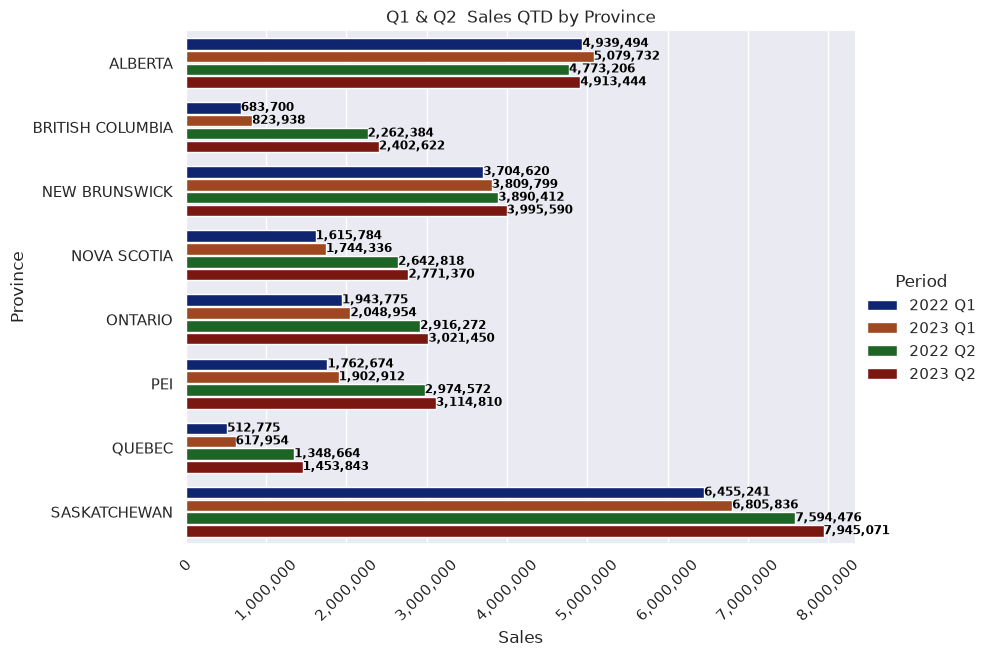

In [231]:
compareMetricByQTD(df, "Sales", ["Q1","Q2"], True, "side-by-side")

**2022 vs 2023 YTD Sales by province**

In [232]:
def compareMetricByYTD(dff, metric, showValues):
    df_year = dff.sort_values(by="PROVINCE", ascending=True);
    df_year = df_year.rename(columns={"PROVINCE":"Province"});
    
    df_agg = df_year.groupby(by=["Province","Year"])[metric].sum().unstack("Year").reset_index();
    data = pd.DataFrame({"Province":df_agg["Province"]});
    for year in df_year["Year"].unique():
        data[year] = df_agg[year];
    
    # Set title
    title = "";
    for year in df_year["Year"].unique():
        title += f"{year} vs ";
    title = f"{title[:-3]} YTD Sales by Province";
    print(title);
    
    # Show aggregated dataframe
    display(data);

    # Create chart
    chart = sns.catplot(data=df_year, kind="bar", x=metric, y="Province", hue="Year", estimator="sum", errorbar=None, palette="dark").set(title=title);
    
    # Add exact values inside the bars
    for ax in chart.axes.flat:
        # Remove 1e6 scientific notation and add commas
        ax.xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
        if showValues == True:
            for container in ax.containers:
                ax.bar_label(
                    container,
                    fmt="{:,.0f}",
                    label_type="edge",
                    color="black",
                    fontsize=9,
                    fontweight="bold"
                );
    
    # Rotate x-axis labels
    chart.tick_params(axis="x", rotation=45);

2022 vs 2023  YTD Sales by Province


,Province,2022,2023
0,ALBERTA,17961143.5,9993176.5
1,BRITISH COLUMBIA,13152771.5,3226560.5
2,NEW BRUNSWICK,15644407.5,7805389.5
3,NOVA SCOTIA,13072291.0,4515706.0
4,ONTARIO,14107964.0,5070404.0
5,PEI,14901162.0,5017722.0
6,QUEBEC,7427711.5,2071796.5
7,SASKATCHEWAN,32213559.0,14750907.0


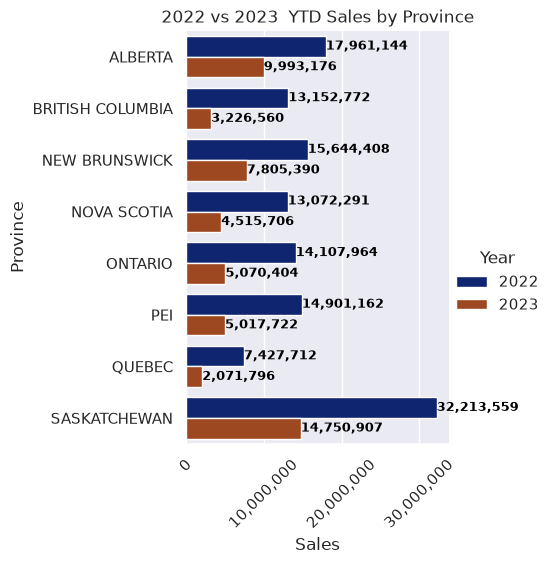

In [233]:
compareMetricByYTD(df, "Sales", True)